<a href="https://colab.research.google.com/github/ipeirotis/introduction-to-databases/blob/master/module5/orientation_model_shap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting Orientation from Profile Likes: A Small ML Model with Shapley Values

**Learning objective:** use SQL to turn profile data into a feature table, train a simple classifier on it, and use Shapley values (SHAP) to see which attributes drive its predictions.

This notebook extends the [books and political views](books_and_political_views.md) example. There, we used lift to predict *Liberal* vs. *Conservative* from favorite books. Here we predict a more sensitive attribute, stated sexual orientation, from everything a profile lists: books, music, movies, TV shows, hobbies, political views, what the person is "looking for", and student/alumni status. The SQL-only version of the lift analysis is in [orientation_and_preferences.sql](orientation_and_preferences.sql).

## Why this example (and how to read it)

In 2013, Kosinski, Stillwell and Graepel showed that Facebook likes alone predict traits that people never disclosed, including sexual orientation ([PNAS, 2013](https://www.pnas.org/doi/10.1073/pnas.1218772110)). This notebook reproduces a small version of that result on the course dataset, so you can see **how little it takes**. The lesson is about privacy: a handful of harmless-looking preferences, combined, leak information that the person did not choose to share.

A few rules we follow throughout:

- **Aggregate results only.** We report accuracy and which attributes matter. We never print or export a prediction for an individual profile.
- **Minimum counts.** Every attribute in the model is listed by at least 20 people, and the lift tables require at least 15 (men) or 6 (women) people per item, so no single person's taste drives a result.
- **Correlation, not identity.** "Gay men in this 2005 sample listed *Madonna* 26x more often" is a statement about a group, in one school, at one point in time. It says nothing about any one person who likes Madonna.

## Setup

**Important:** replace `'nyu-datasets'` with your own Google Cloud project ID for billing/quota (the data itself stays in `nyu-datasets`).

In [1]:
# Authenticate with Google Cloud (only needed in Colab)
try:
    from google.colab import auth
    auth.authenticate_user()
except ImportError:
    pass  # running locally with Application Default Credentials

In [2]:
%pip install -q shap

In [3]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import shap
from google.cloud import bigquery
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix

PROJECT_ID = 'nyu-datasets'  # <-- Replace with your project ID
client = bigquery.Client(project=PROJECT_ID)

def run_query(sql):
    """Run a BigQuery SQL query and return results as a pandas DataFrame."""
    return client.query(sql).to_dataframe()

pd.set_option('display.max_colwidth', 50)

## Step 1: Label the four groups (SQL)

`Profiles.Sex` combined with `Orientation.InterestedIn` gives four groups:

| Code | Sex | Interested in |
|------|-----|---------------|
| `MF` | Male | Women only |
| `MM` | Male | Men, or Men & Women |
| `FM` | Female | Men only |
| `FF` | Female | Women, or Men & Women |

So `MM` and `FF` include everyone who lists any same-sex interest, bisexual profiles included. Profiles that leave Sex blank get `NULL` from the `CASE` and are filtered out.

A trap worth knowing: we can't write `WHERE grp IS NOT NULL` in the same `SELECT` that defines `grp`, because `WHERE` runs before the `SELECT` list is computed. We wrap the query in a derived table and filter outside it.

In [4]:
GROUPS_SQL = """
SELECT *
FROM (
  SELECT
    P.ProfileID,
    CASE
      WHEN P.Sex = 'Male'   AND O.InterestedIn = 'Women'               THEN 'MF'
      WHEN P.Sex = 'Male'   AND O.InterestedIn IN ('Men', 'Men & Women') THEN 'MM'
      WHEN P.Sex = 'Female' AND O.InterestedIn = 'Men'                 THEN 'FM'
      WHEN P.Sex = 'Female' AND O.InterestedIn IN ('Women', 'Men & Women') THEN 'FF'
    END AS grp
  FROM `nyu-datasets.facebook.Profiles` P
    JOIN `nyu-datasets.facebook.Orientation` O ON O.ProfileID = P.ProfileID
)
WHERE grp IS NOT NULL
"""
groups = run_query(GROUPS_SQL)
groups['grp'] = groups['grp'].astype(str)
groups['grp'].value_counts()

grp
FM    7053
MF    5320
MM     719
FF     593
Name: count, dtype: int64

The groups are unbalanced: `MM` is 719 profiles (12% of men in the sample) and `FF` is 593 (8% of women). Of these, 243 men and 522 women list "Men & Women"; without them, `FF` would be only 71 profiles, too few for a model.

## Step 2: What the lift analysis shows (SQL recap)

Before any machine learning, the same lift recipe from the books/politics example already finds strong signals. We compare **within the same sex**: `MM` against `MF`, and `FF` against `FM`. Comparing `MM` against everyone would mostly rediscover gender differences (men list *Scarface* more than women do), which is not what we're after.

The query below stacks all the favorites tables with `UNION ALL`, counts each item per group with `COUNTIF`, and computes a smoothed lift.

In [5]:
LIFT_SQL = """
WITH profile_groups AS (
  {groups}
),
favorites AS (
  SELECT ProfileID, 'book' AS kind, Book AS item FROM `nyu-datasets.facebook.FavoriteBooks`
  UNION ALL
  SELECT ProfileID, 'music', Music FROM `nyu-datasets.facebook.FavoriteMusic`
  UNION ALL
  SELECT ProfileID, 'movie', Movie FROM `nyu-datasets.facebook.FavoriteMovies`
  UNION ALL
  SELECT ProfileID, 'tv', TVShow FROM `nyu-datasets.facebook.FavoriteTVShows`
  UNION ALL
  SELECT ProfileID, 'hobby', Hobby FROM `nyu-datasets.facebook.Hobbies`
),
sizes AS (
  SELECT
    COUNTIF(grp = 'MM') AS n_mm,
    COUNTIF(grp = 'MF') AS n_mf
  FROM profile_groups
)
SELECT
  F.kind,
  F.item,
  COUNTIF(G.grp = 'MM') AS cnt_mm,
  COUNTIF(G.grp = 'MF') AS cnt_mf,
  ROUND(((COUNTIF(G.grp = 'MM') + 0.5) / (ANY_VALUE(S.n_mm) + 1))
      / ((COUNTIF(G.grp = 'MF') + 0.5) / (ANY_VALUE(S.n_mf) + 1)), 1) AS lift_mm_vs_mf
FROM favorites F
  JOIN profile_groups G ON G.ProfileID = F.ProfileID
  CROSS JOIN sizes S
GROUP BY F.kind, F.item
HAVING cnt_mm >= 15
ORDER BY lift_mm_vs_mf DESC
LIMIT 10
""".format(groups=GROUPS_SQL)
run_query(LIFT_SQL)

,kind,item,cnt_mm,cnt_mf,lift_mm_vs_mf
0,movie,Brokeback Mountain,38,6,43.8
1,movie,The Hours,34,8,30.0
2,music,Kylie Minogue,19,6,22.2
3,music,Madonna,67,23,21.2
4,music,Tori Amos,36,13,20.0
5,movie,Camp,22,8,19.6
6,book,Wicked,29,11,19.0
7,movie,Drop Dead Gorgeous,21,8,18.7
8,movie,Clueless,28,11,18.3
9,movie,Angels In America,22,9,17.5


Lifts of 15x to 45x are far larger than anything in the politics example (where the best books had lifts around 2 to 4). Notice also that these items are each listed by only 2% to 10% of `MM` profiles. Any single item covers a small slice of the group; the model's job is to **combine** many such weak-coverage signals.

For women the lifts are smaller. The top items are *But I'm a Cheerleader* (21x), *Sleater-Kinney* (9x), then a long list around 3x to 4x (*Ani DiFranco*, *Tori Amos*, *Portishead*, *Hedwig and the Angry Inch*, *Harold and Maude*). See Step 6 of the `.sql` file for that query.

## Step 3: Build the feature table (SQL)

For the model, every profile becomes a row and every attribute becomes a 0/1 column ("lists *Madonna*", "politics = Very Liberal", "looking for = Dating", ...). SQL does the heavy lifting: it produces a **long** table with one row per (profile, feature), and keeps only features listed by at least 20 labeled profiles. The window function `COUNT(*) OVER (PARTITION BY feature)` counts each feature's support without collapsing the rows.

We deliberately leave out `Sex` and `InterestedIn` (they define the label); identifying fields such as name, hometown, and high school; and major, class year, and relationship status, so the model works from tastes, politics, and what people say they are looking for.

In [6]:
FEATURES_SQL = """
WITH profile_groups AS (
  {groups}
),
long_features AS (
  SELECT ProfileID, CONCAT('book: ', Book) AS feature FROM `nyu-datasets.facebook.FavoriteBooks`
  UNION ALL
  SELECT ProfileID, CONCAT('music: ', Music) FROM `nyu-datasets.facebook.FavoriteMusic`
  UNION ALL
  SELECT ProfileID, CONCAT('movie: ', Movie) FROM `nyu-datasets.facebook.FavoriteMovies`
  UNION ALL
  SELECT ProfileID, CONCAT('tv: ', TVShow) FROM `nyu-datasets.facebook.FavoriteTVShows`
  UNION ALL
  SELECT ProfileID, CONCAT('hobby: ', Hobby) FROM `nyu-datasets.facebook.Hobbies`
  UNION ALL
  SELECT ProfileID, CONCAT('looking for: ', LookingFor) FROM `nyu-datasets.facebook.LookingFor`
  UNION ALL
  SELECT ProfileID, CONCAT('politics: ', COALESCE(PoliticalViews, '(blank)')) FROM `nyu-datasets.facebook.Profiles`
  UNION ALL
  SELECT ProfileID, CONCAT('role: ', COALESCE(Status, '(blank)')) FROM `nyu-datasets.facebook.Profiles`
),
labeled AS (
  SELECT DISTINCT F.ProfileID, F.feature
  FROM long_features F
    JOIN profile_groups G ON G.ProfileID = F.ProfileID
  WHERE F.feature IS NOT NULL
)
SELECT ProfileID, feature
FROM (
  SELECT
    ProfileID,
    feature,
    COUNT(*) OVER (PARTITION BY feature) AS support
  FROM labeled
)
WHERE support >= 20
""".format(groups=GROUPS_SQL)
long = run_query(FEATURES_SQL)
print(f"{len(long):,} (profile, feature) rows, {long.feature.nunique():,} distinct features")
long.sample(8, random_state=1)[['feature']]

314,908 (profile, feature) rows, 2,963 distinct features


,feature
127388,movie: Moonstruck
26945,hobby: Alcohol
306591,tv: Fresh Prince
114329,movie: Great Expectations
118482,movie: Jarhead
184612,music: Coldplay
31515,hobby: Comedy
255015,music: The Animals


Now pivot the long table into a wide 0/1 matrix. Most entries are 0 (each profile lists a few dozen of ~2,000 features), so we use a **sparse** matrix that stores only the 1s.

In [7]:
feature_names = np.array(sorted(long.feature.unique()))
col = pd.Series(np.arange(len(feature_names)), index=feature_names)
row = pd.Series(np.arange(len(groups)), index=groups.ProfileID.values)

long = long[long.ProfileID.isin(row.index)]
X_all = sp.csr_matrix(
    (np.ones(len(long), dtype=np.float32),
     (row[long.ProfileID].values, col[long.feature].values)),
    shape=(len(groups), len(feature_names)),
)
y_all = groups.grp.values
X_all.shape

(13685, 2963)

## Step 4: Model 1, men (`MM` vs `MF`)

We use **logistic regression**, the classification counterpart of linear regression. Each feature gets a weight (coefficient); the model adds up the weights of the features a profile has and turns the sum into a probability. A positive weight pushes toward `MM`, a negative one toward `MF`. This is the same idea as summing log-lifts in the politics example, except the weights are fit jointly, so overlapping signals (*Madonna* and *Kylie Minogue* tend to co-occur) are not double-counted.

Two settings matter:

- `C=0.1` adds **regularization**: it shrinks weights toward zero, so a feature seen in only 20 profiles can't get an extreme weight.
- `class_weight='balanced'` tells the model not to ignore the small `MM` class.

We evaluate with **5-fold cross-validation**: train on 80% of profiles, score the held-out 20%, rotate five times. Every profile gets a prediction from a model that never saw it.

In [8]:
def fit_and_evaluate(pos, neg, C=0.1):
    """Train pos-vs-neg logistic regression; report cross-validated metrics."""
    mask = np.isin(y_all, [pos, neg])
    X = X_all[mask]
    keep = np.asarray(X.sum(axis=0)).ravel() >= 20   # drop features too rare in this subset
    X, names = X[:, keep], feature_names[keep]
    y = (y_all[mask] == pos).astype(int)

    model = LogisticRegression(C=C, class_weight='balanced', max_iter=5000)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
    p = cross_val_predict(model, X, y, cv=cv, method='predict_proba')[:, 1]

    top = np.argsort(-p)[: len(p) // 10]
    print(f"{pos} vs {neg}: {len(y):,} profiles, {y.sum()} {pos} ({y.mean():.1%}), {X.shape[1]:,} features")
    print(f"  AUC                        {roc_auc_score(y, p):.3f}   (0.5 = coin flip, 1.0 = perfect)")
    print(f"  Average precision          {average_precision_score(y, p):.3f}   (baseline = {y.mean():.3f})")
    print(f"  Precision in top 10%       {y[top].mean():.1%}   (baseline = {y.mean():.1%})")

    model.fit(X, y)  # refit on all profiles for the explanation step
    return model, X, y, names

model_m, X_m, y_m, names_m = fit_and_evaluate('MM', 'MF')

MM vs MF: 6,039 profiles, 719 MM (11.9%), 1,489 features
  AUC                        0.869   (0.5 = coin flip, 1.0 = perfect)
  Average precision          0.592   (baseline = 0.119)
  Precision in top 10%       58.9%   (baseline = 11.9%)


How to read these numbers:

- **AUC ≈ 0.87.** Pick a random `MM` profile and a random `MF` profile; 87% of the time the model gives the `MM` profile the higher score.
- **Precision in the top 10% ≈ 59%.** Among the 10% of men the model ranks as most likely `MM`, a bit over half are. That is about 5x the 12% base rate, and it is also wrong for about 4 in 10 of the people it flags. Strong ranking and unreliable individual labels are both true at once; this gap is why "the model says so" is never evidence about a person.

## Step 5: Which attributes drive the predictions? (Shapley values)

A **Shapley value** answers: *for this profile, how much did each feature push the prediction up or down, relative to the average profile?* The values for one profile add up exactly to (that profile's score − the average score). The idea comes from game theory: the features are "players" sharing credit for the outcome.

For a logistic regression with independent features the Shapley value has a simple form:

$$\text{SHAP}_j = w_j \times (x_j - \overline{x_j})$$

the feature's weight times how far the profile's value is from the average. The `shap` library computes this for us, and gives us standard plots.

We look at two summaries, because they answer different questions:

1. **Mean |SHAP|** (global importance): how much a feature moves predictions *across all profiles*. Common features win here, because they affect many people.
2. **Mean SHAP among profiles that list the feature** (punch per person): how much the feature moves the prediction *for someone who has it*. Rare, strong signals win here.

In [9]:
def explain(model, X, names, top=20):
    explainer = shap.LinearExplainer(model, shap.maskers.Independent(X, max_samples=X.shape[0]))
    sv = explainer(X)
    sv.feature_names = list(names)
    values = sv.values.toarray() if sp.issparse(sv.values) else np.asarray(sv.values)

    Xd = X.toarray()
    has = Xd.sum(axis=0)
    when_present = np.where(has > 0, (values * Xd).sum(axis=0) / np.maximum(has, 1), 0)
    table = pd.DataFrame({
        'profiles_with_feature': has.astype(int),
        'weight': model.coef_[0],
        'mean_abs_shap': np.abs(values).mean(axis=0),
        'shap_when_present': when_present,
    }, index=names).round(3)
    return sv, table

sv_m, table_m = explain(model_m, X_m, names_m)
table_m.sort_values('mean_abs_shap', ascending=False).head(15)

,profiles_with_feature,weight,mean_abs_shap,shap_when_present
looking for: Friendship,2542,0.633,0.309,0.367
looking for: Dating,1424,-0.524,0.189,-0.400
politics: (blank),1297,-0.534,0.180,-0.419
looking for: A Relationship,1194,0.543,0.172,0.436
politics: Very Liberal,604,0.847,0.153,0.762
politics: Moderate,1134,-0.473,0.144,-0.384
movie: Pulp Fiction,602,-0.695,0.125,-0.626
looking for: Whatever I can get,1093,0.355,0.105,0.291
movie: Fight Club,689,-0.509,0.103,-0.451
politics: Conservative,377,-0.832,0.097,-0.780


Global importance is dominated by **common** attributes: what the person is "looking for", political views, and mainstream "straight-coded" movies (*Pulp Fiction*, *Fight Club*, *Old School*) whose absence nudges the score up a little for many people. No single one of these is strong, but they apply to thousands of profiles.

The "looking for" weights need care. `MM` profiles fill in that field more often than `MF` (62% vs. 39% list "Friendship"), so listing anything there pushes toward `MM`. "Dating" gets a *negative* weight even though `MM` profiles list it more often (37% vs. 22%): the weights are conditional, and once the model already credits "Friendship" and "A Relationship", adding "Dating" says relatively little. Weights in a model with overlapping features don't read like single-feature lifts.

The beeswarm plot shows the same thing per profile: each dot is one profile, its position is that feature's Shapley value for that profile, and color is the feature value (red = lists it, blue = doesn't).

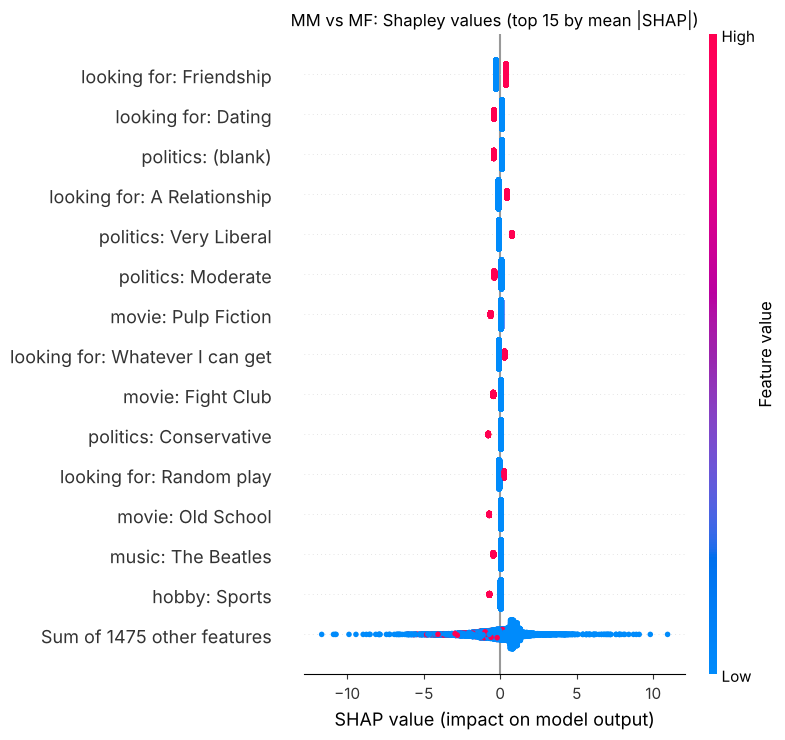

In [10]:
shap.plots.beeswarm(sv_m, max_display=15, show=False)
plt.title('MM vs MF: Shapley values (top 15 by mean |SHAP|)')
plt.tight_layout()
plt.show()

Look at the bottom row, which adds up the remaining ~1,500 features. Its spread (roughly -10 to +10) is far wider than any single row above it (each within about ±1). So the top-15 features are the most important *one at a time*, but most of a profile's score comes from the long tail: many niche items, each listed by few people, that add up.

Now sort by the push a feature gives **to the people who list it**. This recovers the lift table from Step 2: niche items with large per-person effects.

In [11]:
print('Strongest pushes toward MM, among profiles that list the feature:')
display(table_m.sort_values('shap_when_present', ascending=False).head(12))
print('Strongest pushes toward MF:')
display(table_m.sort_values('shap_when_present').head(12))

Strongest pushes toward MM, among profiles that list the feature:


,profiles_with_feature,weight,mean_abs_shap,shap_when_present
music: Madonna,90,1.013,0.030,0.998
movie: Moulin Rouge,116,0.888,0.033,0.871
movie: Brokeback Mountain,44,0.870,0.013,0.863
music: Rufus Wainwright,106,0.872,0.030,0.856
politics: Very Conservative,77,0.841,0.021,0.830
politics: Very Liberal,604,0.847,0.153,0.762
music: Scissor Sisters,50,0.744,0.012,0.738
movie: Saved,37,0.719,0.009,0.715
movie: Clueless,39,0.717,0.009,0.712
music: Tori Amos,49,0.673,0.011,0.667


Strongest pushes toward MF:


,profiles_with_feature,weight,mean_abs_shap,shap_when_present
politics: Conservative,377,-0.832,0.097,-0.780
movie: Old School,363,-0.764,0.086,-0.718
hobby: Baseball,193,-0.741,0.046,-0.718
hobby: Sports,302,-0.738,0.070,-0.701
music: Rap,136,-0.708,0.031,-0.692
hobby: Basketball,281,-0.681,0.060,-0.649
movie: Snatch,252,-0.657,0.053,-0.630
hobby: Snowboarding,130,-0.640,0.027,-0.627
movie: Pulp Fiction,602,-0.695,0.125,-0.626
movie: City Of God,260,-0.592,0.049,-0.567


The two rankings tell complementary stories. **Mean |SHAP|** says that profile-level attributes (politics, "looking for") and common mainstream tastes do most of the work across the population. **SHAP when present** says that for the minority of profiles that list *Brokeback Mountain*, *Madonna* or *Scissor Sisters*, that one item moves the prediction a lot. Note that "Very Liberal" appears in both lists: it is common *and* strong. "Very Conservative" also pushes toward `MM` (3.1% of `MM` vs. 1.0% of `MF` choose it); on early Facebook the extreme political labels were often picked as a joke, so read it as "picked an extreme label" more than as politics. The lift table only shows the second view; Shapley values give both.

## Step 6: Model 2, women (`FF` vs `FM`)

Same pipeline: 593 `FF` profiles against 7,053 `FM`.

In [12]:
model_f, X_f, y_f, names_f = fit_and_evaluate('FF', 'FM')

FF vs FM: 7,646 profiles, 593 FF (7.8%), 1,822 features
  AUC                        0.780   (0.5 = coin flip, 1.0 = perfect)
  Average precision          0.273   (baseline = 0.078)
  Precision in top 10%       28.3%   (baseline = 7.8%)


The women's model is weaker than the men's: AUC ≈ 0.78, and in the top 10% only about 28% of flagged profiles are `FF` (base rate 8%). That is still 3.5x better than chance, and it is wrong for more than 7 in 10 of the people it flags. This is the **base-rate problem**: when a group is small, even a decent ranking produces mostly false positives.

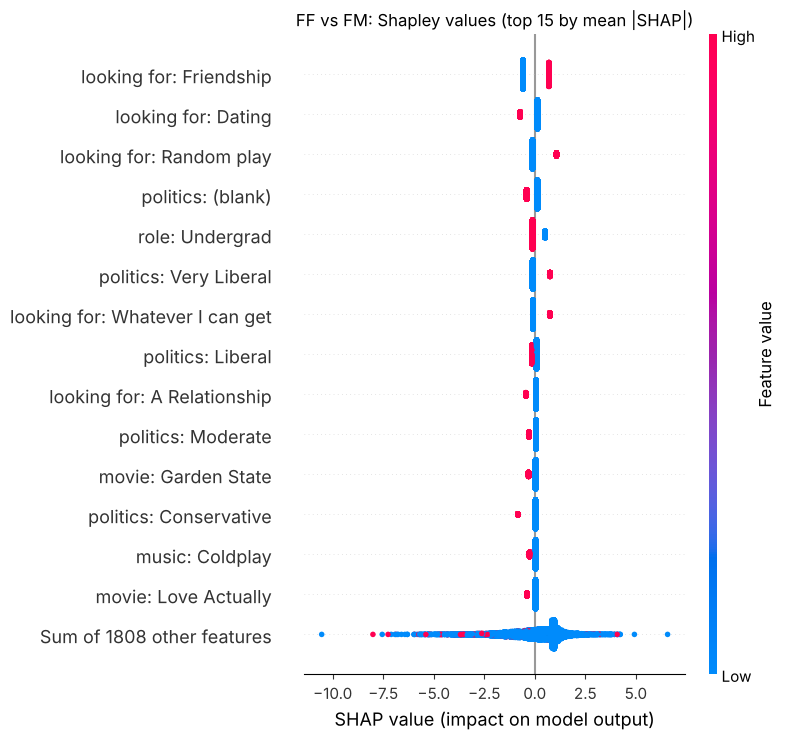

In [13]:
sv_f, table_f = explain(model_f, X_f, names_f)
shap.plots.beeswarm(sv_f, max_display=15, show=False)
plt.title('FF vs FM: Shapley values (top 15 by mean |SHAP|)')
plt.tight_layout()
plt.show()

In [14]:
print('Strongest pushes toward FF, among profiles that list the feature (at least 20 women list each):')
display(table_f.sort_values('shap_when_present', ascending=False).head(12))

Strongest pushes toward FF, among profiles that list the feature (at least 20 women list each):


,profiles_with_feature,weight,mean_abs_shap,shap_when_present
looking for: Random play,724,1.187,0.203,1.074
movie: But I m A Cheerleader,25,0.794,0.005,0.791
tv: The L Word,24,0.784,0.005,0.781
politics: Very Liberal,900,0.853,0.177,0.752
looking for: Whatever I can get,778,0.828,0.151,0.744
looking for: Friendship,3451,1.279,0.633,0.702
music: Ani Difranco,193,0.672,0.033,0.655
hobby: Languages,83,0.657,0.014,0.650
music: Pretty Girls Make Graves,20,0.638,0.003,0.637
movie: Sin City,128,0.647,0.021,0.636


For women, the strongest global signals are **profile fields**, not tastes: "looking for" (especially "Random play" and "Whatever I can get", which 22% of `FF` vs. 8–9% of `FM` list) and political views. The tastes in the global top 15 are mainstream ones whose *absence* nudges toward `FF` (*Garden State*, *Coldplay*, *Love Actually*).

Sorted by push when present, the niche items from the lift table come back: *But I'm a Cheerleader*, *The L Word*, *Ani DiFranco*. Several of these are listed by only 20 to 25 women in total, so treat each one as a hint, not a finding.

## Step 7: All four groups at once

Finally, the four-way version: one multinomial logistic regression that predicts `MF` / `MM` / `FM` / `FF` from the same features. **We do not give the model `Sex`**, so it has to infer gender from tastes too.

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
model_4 = LogisticRegression(C=0.1, class_weight='balanced', max_iter=5000)
p4 = cross_val_predict(model_4, X_all, y_all, cv=cv, method='predict_proba')
classes = np.array(sorted(set(y_all)))
pred4 = classes[p4.argmax(axis=1)]

cm = pd.DataFrame(confusion_matrix(y_all, pred4, labels=classes),
                  index=[f'actual {c}' for c in classes],
                  columns=[f'pred {c}' for c in classes])
display(cm)
for i, c in enumerate(classes):
    print(f"{c}: one-vs-rest AUC = {roc_auc_score(y_all == c, p4[:, i]):.3f}")

,pred FF,pred FM,pred MF,pred MM
actual FF,236,183,84,90
actual FM,837,4789,958,469
actual MF,401,680,3767,472
actual MM,112,117,152,338


FF: one-vs-rest AUC = 0.766
FM: one-vs-rest AUC = 0.852
MF: one-vs-rest AUC = 0.882
MM: one-vs-rest AUC = 0.828


Reading the confusion matrix by rows: the model guesses gender from tastes correctly for most profiles, but not all (roughly 1 in 7 `FM` profiles is predicted `MF`, and 1 in 8 `MF` is predicted `FM`). Within each sex, `class_weight='balanced'` makes the model flag far more profiles as `MM` or `FF` than actually are (about 1,370 predicted `MM` for 719 actual, and about 1,590 predicted `FF` for 593 actual). Most of those flags are false positives, as in Steps 4 and 6. Only 47% of `MM` and 40% of `FF` profiles land in their own column.

Which features does each class lean on? For a multinomial model, `shap` returns one set of Shapley values per class.

In [16]:
model_4.fit(X_all, y_all)
explainer4 = shap.LinearExplainer(model_4, shap.maskers.Independent(X_all, max_samples=X_all.shape[0]))
sv4 = explainer4(X_all)
vals4 = sv4.values.toarray() if sp.issparse(sv4.values) else np.asarray(sv4.values)  # (profiles, features, classes)

top_features = pd.DataFrame({
    c: pd.Series(np.abs(vals4[:, :, i]).mean(axis=0), index=feature_names).nlargest(8).index
    for i, c in enumerate(model_4.classes_)
})
top_features.index = range(1, 9)
top_features

,FF,FM,MF,MM
1,looking for: Friendship,politics: (blank),looking for: Friendship,looking for: A Relationship
2,looking for: Dating,role: Undergrad,looking for: Dating,politics: (blank)
3,looking for: A Relationship,looking for: Friendship,politics: Very Liberal,politics: Moderate
4,looking for: Random play,looking for: Random play,hobby: Shopping,role: Undergrad
5,politics: Very Liberal,politics: Liberal,politics: Liberal,politics: Liberal
6,looking for: Whatever I can get,looking for: Whatever I can get,hobby: Dancing,movie: Old School
7,politics: Conservative,looking for: Dating,politics: Moderate,movie: Garden State
8,role: Alumnus/Alumna,hobby: Shopping,politics: Conservative,movie: Pulp Fiction


By mean |SHAP|, all four classes lean mostly on **profile fields** ("looking for", political views, student/alumni status), with a few common tastes mixed in (*Shopping* and *Dancing* for `FM` and `MF`; *Old School*, *Garden State* and *Pulp Fiction* for `MM`). As in Step 5, the niche tastes with large per-person effects sit lower in this ranking because few people list them. Try computing the "SHAP when present" table for each class as an exercise.

## Takeaways

**SQL concepts used**
- `CASE` to build labels from two columns; a derived table to filter on a computed column.
- `UNION ALL` to stack similar tables into one long table.
- `COUNTIF` to count several groups in one `GROUP BY` instead of one temp table per group.
- A window function (`COUNT(*) OVER (PARTITION BY ...)`) to filter rows by group size without collapsing them.

**Analytics concepts**
- Compare within the same sex, or the result mostly measures gender.
- Logistic regression generalizes the "sum of log-lifts" scorer from the politics example.
- Shapley values split each prediction into per-feature contributions. Mean |SHAP| ranks features by population-wide impact; SHAP-when-present ranks them by per-person impact.
- A high AUC can coexist with mostly-wrong individual flags when the group is small (the base-rate problem).

**Caveats**
- The data is self-reported, from one university around 2005. Who chose to fill in "Interested in" is itself selective, and tastes have changed.
- Profile fields on early Facebook were often filled in as jokes (extreme political labels, "Random play"), so those fields are noisy.
- `MM` and `FF` mix people who list only their own sex with people who list "Men & Women"; the two subgroups may differ, and this notebook doesn't separate them.
- These are population-level correlations. They describe groups in this sample, not individuals.

**Privacy**

Nobody in this dataset was asked whether their favorite movies could be used to guess their orientation. A few dozen likes were enough to rank people far better than chance. Platforms, advertisers, and data brokers can do the same with much more data. When you build models on behavioral data in your own work, ask which sensitive attributes they could reveal, even when those attributes are not in the data.